# Questão 3 — Derivadas parciais, diferenciabilidade e continuidade

Modelo comparativo de
$$
f(x,y)=\begin{cases}\dfrac{xy}{\sqrt{x^2+y^2}},&(x,y)\ne(0,0),\\0,&(x,y)=(0,0),\end{cases}
\qquad
g(x,y)=\begin{cases}\dfrac{xy}{x^2+y^2},&(x,y)\ne(0,0),\\0,&(x,y)=(0,0).\end{cases}
$$

**Como executar:** use Python 3.10 ou superior com as bibliotecas de `requirements.txt` e execute todas as células em ordem. Este notebook é independente das outras questões. Os controles precisam de um kernel Python ativo com ipywidgets (VS Code/Jupyter); a visualização estática do GitHub não executa os controles.

Cada item alterna **Análise na mão ✍️** e **Código 💻**. Gráficos e valores numéricos ajudam a investigar; as conclusões são justificadas por demonstrações. Fonte: PDF do trabalho de Cálculo II — UFAM, questões 3 e orientações gerais.


In [1]:
# 💻 Configuração independente
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import ipywidgets as widgets
from IPython.display import display, Markdown

def avaliar_funcao(nome, x, y):
    """Avaliação vetorizada, com o valor prescrito na origem e sem divisão por zero."""
    if nome not in ('f', 'g'):
        raise ValueError('Escolha f ou g.')
    x, y = np.broadcast_arrays(np.asarray(x, dtype=float), np.asarray(y, dtype=float))
    r = np.hypot(x, y)
    denominador = r if nome == 'f' else r*r
    return np.divide(x*y, denominador, out=np.zeros_like(r), where=r > 0)

def quociente_erro(nome, h, k):
    """L=0 para as duas funções. Na origem o quociente NÃO está definido."""
    h, k = np.broadcast_arrays(np.asarray(h, dtype=float), np.asarray(k, dtype=float))
    r = np.hypot(h, k)
    return np.divide(avaliar_funcao(nome, h, k), r,
                     out=np.full_like(r, np.nan), where=r > 0)

print('Configuração carregada. f(0,0) =', float(avaliar_funcao('f', 0, 0)),
      '| g(0,0) =', float(avaliar_funcao('g', 0, 0)))


Configuração carregada. f(0,0) = 0.0 | g(0,0) = 0.0


## Item 1 — Derivadas parciais na origem pela definição

### Análise na mão ✍️
Para uma função $F$, as definições são
$$
F_x(0,0)=\lim_{h\to0}\frac{F(h,0)-F(0,0)}h,
\qquad F_y(0,0)=\lim_{k\to0}\frac{F(0,k)-F(0,0)}k.
$$
Em ambas as funções, $F(h,0)=F(0,k)=F(0,0)=0$. Assim, para todo incremento não nulo, os dois quocientes são exatamente zero. Os limites bilaterais existem e
$$
\boxed{f_x(0,0)=f_y(0,0)=g_x(0,0)=g_y(0,0)=0.}
$$
Usamos a definição porque as fórmulas de derivadas válidas fora da origem não podem ser simplesmente avaliadas em um ponto onde seus denominadores se anulam.


In [2]:
# 💻 Quocientes incrementais: incrementos de ambos os sinais
incrementos = np.array([-1e-1, -1e-3, -1e-6, 1e-6, 1e-3, 1e-1])
print('      incremento      f_x: quociente  f_y: quociente  g_x: quociente  g_y: quociente')
for t in incrementos:
    valores = [float(avaliar_funcao(n, t, 0)/t) for n in ('f','g')]
    valores_y = [float(avaliar_funcao(n, 0, t)/t) for n in ('f','g')]
    print(f'{t:16.1e} {valores[0]:16.1f} {valores_y[0]:16.1f} {valores[1]:16.1f} {valores_y[1]:16.1f}')


      incremento      f_x: quociente  f_y: quociente  g_x: quociente  g_y: quociente
        -1.0e-01              0.0              0.0              0.0              0.0
        -1.0e-03              0.0              0.0              0.0              0.0
        -1.0e-06              0.0              0.0              0.0              0.0
         1.0e-06              0.0              0.0              0.0              0.0
         1.0e-03              0.0              0.0              0.0              0.0
         1.0e-01              0.0              0.0              0.0              0.0


## Item 2 — Cortes por $x=0$ e $y=0$

### Análise na mão ✍️
As curvas de corte são $(0,t,0)$ e $(t,0,0)$, para as duas superfícies. São retas horizontais, cujas tangentes têm direções $(0,1,0)$ e $(1,0,0)$: as inclinações observadas são zero.

Esses cortes só descrevem duas direções. Na diagonal $x=y=t$, temos
$$
f(t,t)=\frac{|t|}{\sqrt2},\qquad
g(t,t)=\frac12\ (t\ne0),\quad g(0,0)=0.
$$
Em $f$, a diagonal tem uma ponta; em $g$, ela revela uma descontinuidade. Os eixos sozinhos escondem ambos os problemas.


**Nota sobre a malha 3D:** em g, uma pequena vizinhança da origem é omitida somente na superfície desenhada para evitar interpolação artificial da descontinuidade. O valor g(0,0)=0 é marcado separadamente. Esse recorte visual não exclui pontos do domínio, que continua sendo todo o plano.

In [3]:
# 💻 Superfícies com os cortes coordenados e o valor prescrito na origem
v = np.linspace(-1, 1, 81)
X, Y = np.meshgrid(v, v)
r = np.hypot(X, Y)
fig = make_subplots(rows=1, cols=2, specs=[[{'type':'scene'}, {'type':'scene'}]],
                    subplot_titles=('f: contínua, com comportamento angular na origem',
                                    'g: a malha não prova continuidade'))
for col, nome in enumerate(('f','g'), 1):
    Z = avaliar_funcao(nome, X, Y)
    # O ponto prescrito é exibido separadamente; não ligamos o vértice de g aos vizinhos.
    if nome == 'g':
        Z = np.where(r < 0.03, np.nan, Z)
    fig.add_trace(go.Surface(x=X,y=Y,z=Z,colorscale='Viridis',opacity=.75,
                            showscale=False, name=nome, connectgaps=False),row=1,col=col)
    for xx, yy, rotulo, cor in [(v,np.zeros_like(v),'y = 0','#e63946'),
                               (np.zeros_like(v),v,'x = 0','#2374d8')]:
        fig.add_trace(go.Scatter3d(x=xx,y=yy,z=np.zeros_like(v),mode='lines',
                                  name=nome+': '+rotulo,line=dict(color=cor,width=7)),row=1,col=col)
    fig.add_trace(go.Scatter3d(x=[0],y=[0],z=[0],mode='markers',name=nome+'(0,0) = 0',
                              marker=dict(color='black',size=5)),row=1,col=col)
fig.update_layout(height=530, margin=dict(l=0,r=0,t=55,b=0))
fig.update_scenes(xaxis_title='x',yaxis_title='y',zaxis_title='z',aspectmode='cube')
fig.show()


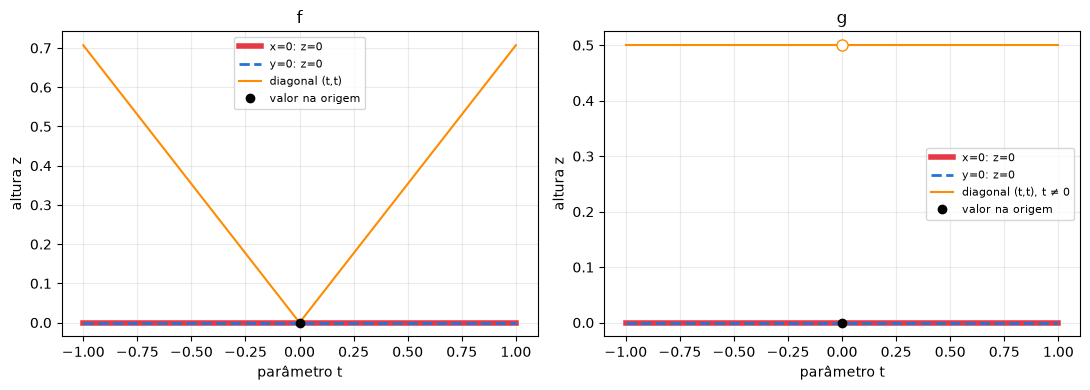

In [4]:
# 💻 Cortes 2D: eixos horizontais e diagonal como contraste
fig2, axs = plt.subplots(1, 2, figsize=(11, 4))
t = np.linspace(-1,1,401)
for ax, nome in zip(axs, ('f','g')):
    ax.plot(t,np.zeros_like(t),color='#e63946',lw=4,label='x=0: z=0')
    ax.plot(t,np.zeros_like(t),color='#2374d8',ls='--',lw=2,label='y=0: z=0')
    if nome == 'f':
        ax.plot(t,avaliar_funcao(nome,t,t),color='darkorange',label='diagonal (t,t)')
    else:
        for trecho in (t[t<0],t[t>0]):
            ax.plot(trecho,np.full_like(trecho,.5),color='darkorange')
        ax.plot([],[],color='darkorange',label='diagonal (t,t), t ≠ 0')
        ax.plot(0,.5,'o',mfc='white',mec='darkorange',ms=8)
    ax.plot(0,0,'ko',label='valor na origem')
    ax.set(title=nome, xlabel='parâmetro t', ylabel='altura z')
    ax.grid(alpha=.25); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


## Item 3 — Aplicação linear candidata

### Análise na mão ✍️
Se uma função for diferenciável, sua derivada total deve ser a aplicação linear determinada por suas parciais. Para as duas funções:
$$
L_f(h,k)=f_x(0,0)h+f_y(0,0)k=0,
\qquad L_g(h,k)=0.
$$
A aproximação afim candidata é $F(0,0)+L(h,k)=0$, o plano $z=0$. **Por enquanto ele é apenas candidato**, não um plano tangente justificado pelo diferencial. Precisamos verificar o erro em relação à distância até a origem.


In [5]:
# 💻 Construção simbólica da aplicação linear (coeficientes obtidos pela definição)
h, k = sp.symbols('h k', real=True)
L_f = sp.Integer(0)*h + sp.Integer(0)*k
L_g = sp.Integer(0)*h + sp.Integer(0)*k
print('L_f(h,k) =', L_f, '| L_g(h,k) =', L_g)
print('A validade da aproximação será decidida no item 4.')


L_f(h,k) = 0 | L_g(h,k) = 0
A validade da aproximação será decidida no item 4.


## Item 4 — Erro da aproximação e diferenciabilidade

### Análise na mão ✍️
A definição exige, com $\rho=\sqrt{h^2+k^2}$,
$$
Q_F(h,k)=\frac{F(h,k)-F(0,0)-L(h,k)}\rho\longrightarrow0.
$$
Equivalentemente, podemos usar $|Q_F|$. Aqui:
$$
Q_f=\frac{hk}{h^2+k^2},\qquad Q_g=\frac{hk}{(h^2+k^2)^{3/2}}.
$$
Nos eixos, ambos são zero. Na diagonal $(h,k)=(t,t)$, $t\ne0$:
$$
Q_f(t,t)=\frac12,\qquad Q_g(t,t)=\frac1{2\sqrt2\,|t|}.
$$
Logo $Q_f$ não tende a zero e $Q_g$ cresce sem limite: **nenhuma das duas funções é diferenciável na origem**. Um único caminho que contrarie o limite exigido basta para refutá-lo; vários caminhos favoráveis não bastam para prová-lo.

Mais geralmente, na reta $k=mh$:
$$
Q_f(t,mt)=\frac{m}{1+m^2},\quad
Q_g(t,mt)=\frac{m}{(1+m^2)^{3/2}|t|}.
$$
Na parábola $(t,t^2)$:
$$
Q_f=\frac{t}{1+t^2}\to0,\qquad
Q_g=\frac{\operatorname{sgn}(t)}{(1+t^2)^{3/2}}\to\begin{cases}1&t\to0^+,\\-1&t\to0^-.\end{cases}
$$
Isso mostra por que também é útil investigar sinais e trajetórias curvas.


In [6]:
# 💻 Trajetórias usadas pelo comparador; t nunca será zero nos quocientes
TRAJETORIAS = ['Eixo x', 'Eixo y', 'Diagonal y=x', 'Diagonal y=-x', 'Reta y=m x', 'Parábola y=x²']
def trajetoria(tipo, t, m=1.0):
    t = np.asarray(t, dtype=float)
    if tipo == 'Eixo x': return t, np.zeros_like(t)
    if tipo == 'Eixo y': return np.zeros_like(t), t
    if tipo == 'Diagonal y=x': return t, t
    if tipo == 'Diagonal y=-x': return t, -t
    if tipo == 'Reta y=m x': return t, m*t
    if tipo == 'Parábola y=x²': return t, t*t
    raise ValueError('Trajetória desconhecida.')

def dados_exploracao(tipo, m=1.0, sinal=1, expoente=3):
    """Dados puros: reutilizados pelos gráficos e pelas verificações."""
    t = sinal*np.logspace(-1,-7,100)
    hh, kk = trajetoria(tipo,t,m)
    tp = sinal*10.0**(-expoente)
    hp, kp = trajetoria(tipo,tp,m)
    return dict(t=t,h=hh,k=kk,hp=float(hp),kp=float(kp),
                f=avaliar_funcao('f',hh,kk),g=avaliar_funcao('g',hh,kk),
                Qf=quociente_erro('f',hh,kk),Qg=quociente_erro('g',hh,kk))

# Tabela de referência independente dos controles
print('Diagonal (t,t):')
print('      t          f(t,t)          g(t,t)          Q_f              Q_g')
for t0 in [1e-1,1e-2,1e-3,1e-4,1e-6]:
    print(f'{t0:9.1e} {float(avaliar_funcao("f",t0,t0)):15.6g} '
          f'{float(avaliar_funcao("g",t0,t0)):15.6g} '
          f'{float(quociente_erro("f",t0,t0)):15.6g} {float(quociente_erro("g",t0,t0)):15.6g}')


Diagonal (t,t):
      t          f(t,t)          g(t,t)          Q_f              Q_g
  1.0e-01       0.0707107             0.5             0.5         3.53553
  1.0e-02      0.00707107             0.5             0.5         35.3553
  1.0e-03     0.000707107             0.5             0.5         353.553
  1.0e-04     7.07107e-05             0.5             0.5         3535.53
  1.0e-06     7.07107e-07             0.5             0.5          353553


### Comparador interativo 💻
Escolha uma trajetória; o coeficiente $m$ atua somente em **Reta y=m x**. Troque o sinal para investigar os dois lados do parâmetro. O controle $p$ escolhe o ponto destacado com $|t|=10^{-p}$.

A curva colorida em cada superfície acompanha a trajetória. Abaixo, os gráficos separam o valor da função e o quociente de erro (com sinal). O eixo horizontal é $|t|$ em escala logarítmica, com a origem sendo aproximada para a direita. O quociente não é avaliado em $t=0$.


In [7]:
# 💻 Construção dos gráficos e atualização dos painéis sem acumular resultados

def construir_exploracao(tipo, m=1.0, sinal=1, expoente=3):
    d = dados_exploracao(tipo,m,sinal,expoente)
    # Superfície local: acompanha a escala do ponto escolhido, inclusive para m grande.
    lado = max(abs(d['hp']),abs(d['kp']))*1.5
    v = np.linspace(-lado,lado,61)
    xx, yy = np.meshgrid(v,v)
    raio = np.hypot(xx,yy)
    tt = sinal*np.linspace(0,2*10.0**(-expoente),160)[1:]
    hx, ky = trajetoria(tipo,tt,m)
    fig = make_subplots(rows=1,cols=2,specs=[[{'type':'scene'},{'type':'scene'}]],
                        subplot_titles=('f: aproximação à origem','g: aproximação à origem'))
    for col,nome in enumerate(('f','g'),1):
        zz=avaliar_funcao(nome,xx,yy)
        if nome=='g': zz=np.where(raio<lado*.04,np.nan,zz)
        fig.add_trace(go.Surface(x=xx,y=yy,z=zz,showscale=False,colorscale='Viridis',
                                opacity=.65,connectgaps=False),row=1,col=col)
        fig.add_trace(go.Scatter3d(x=hx,y=ky,z=avaliar_funcao(nome,hx,ky),mode='lines',
                                  name=nome+': trajetória',line=dict(color='red',width=6)),row=1,col=col)
        fig.add_trace(go.Scatter3d(x=[d['hp']],y=[d['kp']],
                                  z=[float(avaliar_funcao(nome,d['hp'],d['kp']))],
                                  mode='markers',name=nome+': ponto escolhido',
                                  marker=dict(color='red',size=6)),row=1,col=col)
        fig.add_trace(go.Scatter3d(x=[0],y=[0],z=[0],mode='markers',name=nome+': origem',
                                  marker=dict(color='black',size=5)),row=1,col=col)
    fig.update_layout(height=450,margin=dict(l=0,r=0,t=40,b=0),title=tipo)
    fig.update_scenes(xaxis_title='h',yaxis_title='k',zaxis_title='altura',aspectmode='cube')
    curvas=make_subplots(rows=1,cols=2,subplot_titles=('Valor da função','Erro dividido pela distância'))
    for nome,cor in [('f','#2374d8'),('g','#d62828')]:
        curvas.add_trace(go.Scatter(x=np.abs(d['t']),y=d[nome],name=nome,
                                    line=dict(color=cor)),row=1,col=1)
        curvas.add_trace(go.Scatter(x=np.abs(d['t']),y=d['Q'+nome],name='Q_'+nome,
                                    line=dict(color=cor)),row=1,col=2)
    curvas.update_xaxes(type='log',autorange='reversed',title_text='|t| → 0')
    curvas.update_yaxes(title_text='F(h,k)',row=1,col=1)
    curvas.update_yaxes(title_text='Q_F(h,k)',row=1,col=2)
    curvas.add_hline(y=0,line_dash='dot',line_color='gray')
    curvas.update_layout(height=360,margin=dict(l=45,r=20,t=45,b=40))
    hp,kp=d['hp'],d['kp']
    texto=(f'**Ponto escolhido:** (h,k)=({hp:.5g}, {kp:.5g}); '
           f'distância = {np.hypot(hp,kp):.5g}.  \\n'
           f'**f:** valor = {float(avaliar_funcao("f",hp,kp)):.6g}; '
           f'Q_f = {float(quociente_erro("f",hp,kp)):.6g}.  \\n'
           f'**g:** valor = {float(avaliar_funcao("g",hp,kp)):.6g}; '
           f'Q_g = {float(quociente_erro("g",hp,kp)):.6g}.')
    return fig,curvas,texto.replace('\\n','\n')

seletor=widgets.Dropdown(options=TRAJETORIAS,value='Diagonal y=x',description='Trajetória:',
                        layout=widgets.Layout(width='330px'))
coeficiente=widgets.FloatSlider(value=1,min=-3,max=3,step=.25,description='m:',continuous_update=False)
lado_parametro=widgets.Dropdown(options=[('t > 0',1),('t < 0',-1)],value=1,description='Lado:')
expoente=widgets.IntSlider(value=3,min=1,max=7,description='p:',continuous_update=False)
display(widgets.VBox([seletor,coeficiente,widgets.HBox([lado_parametro,expoente])]))
painel_texto=display(Markdown('Preparando o comparador…'),display_id=True)
painel_3d=display(go.Figure(),display_id=True)
painel_curvas=display(go.Figure(),display_id=True)

def atualizar_comparador(change=None):
    coeficiente.disabled=seletor.value!='Reta y=m x'
    f3d,fc,txt=construir_exploracao(seletor.value,coeficiente.value,lado_parametro.value,expoente.value)
    painel_texto.update(Markdown(txt))
    painel_3d.update(f3d)
    painel_curvas.update(fc)

for controle in (seletor,coeficiente,lado_parametro,expoente):
    controle.observe(atualizar_comparador,names='value')
atualizar_comparador()


**Ponto escolhido:** (h,k)=(0.001, 0.001); distância = 0.0014142.  
**f:** valor = 0.000707107; Q_f = 0.5.  
**g:** valor = 0.5; Q_g = 353.553.

## Item 5 — Continuidade e relações lógicas

### Análise na mão ✍️ — Continuidade de $f$
A desigualdade $2|xy|\le x^2+y^2$ vem de $(|x|-|y|)^2\ge0$. Portanto, fora da origem,
$$
|f(x,y)|=\frac{|xy|}{\sqrt{x^2+y^2}}\le\frac{\sqrt{x^2+y^2}}2\longrightarrow0.
$$
Como $f(0,0)=0$, **$f$ é contínua na origem**. Em termos de $\varepsilon$ e $\delta$, para qualquer $\varepsilon>0$, escolha $\delta=2\varepsilon$; se $0<\sqrt{x^2+y^2}<\delta$, então $|f(x,y)-f(0,0)|<\varepsilon$. A estimativa vale para todos os caminhos, ao contrário de uma amostragem de trajetórias.

### Análise na mão ✍️ — Descontinuidade de $g$
No eixo, $g(t,0)=0$; na diagonal, $g(t,t)=1/2$ para $t\ne0$. Esses limites são diferentes; **o limite de $g$ na origem não existe**, logo $g$ não é contínua nesse ponto. Alterar somente $g(0,0)$ não resolveria a inexistência do limite.


In [8]:
# 💻 Evidência numérica para a estimativa global de f (a prova está acima)
angulos=np.linspace(0,2*np.pi,721)
print('     raio         máximo amostrado |f|       limite superior r/2')
for rho in [1,.1,.01,.001]:
    valores=np.abs(avaliar_funcao('f',rho*np.cos(angulos),rho*np.sin(angulos)))
    print(f'{rho:10.3g} {np.max(valores):26.8g} {rho/2:25.8g}')
print('\ng: eixo → 0; diagonal → 1/2. Ver comparador do item 4.')


     raio         máximo amostrado |f|       limite superior r/2
         1                        0.5                       0.5
       0.1                       0.05                      0.05
      0.01                      0.005                     0.005
     0.001                     0.0005                    0.0005

g: eixo → 0; diagonal → 1/2. Ver comparador do item 4.


### Relações lógicas e conclusão

| Propriedade na origem | $f$ | $g$ |
|:---|:---:|:---:|
| Duas derivadas parciais existem | Sim, ambas zero | Sim, ambas zero |
| Continuidade | Sim | Não |
| Diferenciabilidade | Não | Não |

- **Diferenciabilidade implica existência das parciais**: basta restringir a aproximação linear aos eixos.
- **Diferenciabilidade implica continuidade**: se $F(p+u)=F(p)+L(u)+R(u)$ e $R(u)/\|u\|\to0$, então $L(u)\to0$ por linearidade em dimensão finita e $R(u)\to0$; portanto $F(p+u)\to F(p)$.
- **Parciais existentes não implicam continuidade**: $g$ é o contraexemplo.
- **Continuidade e parciais existentes, juntas, não implicam diferenciabilidade**: $f$ é o contraexemplo.
- Uma condição suficiente, que não se deve confundir com condição necessária, é ter parciais existentes e contínuas em uma vizinhança do ponto. Fora da origem, as duas funções são suaves; o problema estudado aqui é precisamente a origem.

**Resposta à pergunta orientadora:** duas inclinações coordenadas não controlam o erro em todas as direções. Diferenciabilidade exige um erro que seja pequeno em relação à distância ao ponto, independentemente do caminho de aproximação.


## Conferências e roteiro de apresentação

A célula abaixo confere valores de referência e as fórmulas dos caminhos. Ela detecta erros de implementação; as demonstrações dos itens anteriores continuam sendo a justificativa matemática.


In [9]:
# 💻 Verificações reproduzíveis dos casos decisivos
for nome in ('f','g'):
    assert float(avaliar_funcao(nome,0,0)) == 0
    assert np.isnan(float(quociente_erro(nome,0,0)))
    assert np.all(avaliar_funcao(nome,incrementos,0) == 0)
    assert np.all(avaliar_funcao(nome,0,incrementos) == 0)
for sinal in (-1,1):
    t=sinal*np.logspace(-1,-7,25)
    np.testing.assert_allclose(quociente_erro('f',t,t),.5)
    np.testing.assert_allclose(quociente_erro('g',t,t),1/(2*np.sqrt(2)*np.abs(t)))
    np.testing.assert_allclose(quociente_erro('f',t,-t),-.5)
    np.testing.assert_allclose(quociente_erro('f',t,t*t),t/(1+t*t))
    np.testing.assert_allclose(quociente_erro('g',t,t*t),sinal/(1+t*t)**1.5)
    for m0 in (-2,0,.5,2):
        np.testing.assert_allclose(quociente_erro('f',t,m0*t),m0/(1+m0*m0),atol=1e-15)
np.testing.assert_allclose(avaliar_funcao('g',incrementos,incrementos),.5)
for tipo in TRAJETORIAS:
    for sinal in (-1,1):
        d=dados_exploracao(tipo,m=-2,sinal=sinal,expoente=7)
        assert all(np.all(np.isfinite(d[chave])) for chave in ('f','g','Qf','Qg'))
print('Conferências matemáticas e numéricas: OK.')


Conferências matemáticas e numéricas: OK.


**Roteiro para demonstrar:**

1. Mostrar que as quatro parciais são zero pela definição e pelos cortes coordenados.
2. Selecionar a diagonal: o quociente de f permanece em 1/2 e o de g cresce.
3. Selecionar o eixo: ambos os quocientes são zero, o que evidencia a insuficiência de testar só os eixos.
4. Selecionar a parábola e trocar o sinal de t; explicar a diferença entre os limites laterais de Q_g.
5. Justificar a continuidade de f pela desigualdade global e refutar a de g com os dois caminhos.

**Situação do trabalho:** notebook individual da questão 3. A questão 4 está no notebook individual `questao4.ipynb`, que não precisa ser executado para usar este arquivo. A integração com os demais notebooks e com o relatório fica para quando a equipe autorizar.
